# Tugas 3
## CELL 1 — Install library:
Menginstal library Python yang dibutuhkan untuk analisis data, manipulasi teks, dan pemodelan seperti pandas, openpyxl, Sastrawi, gensim, scikit-learn, matplotlib, dan seaborn.

In [1]:
%pip install pandas openpyxl Sastrawi gensim scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 64.2 MB/s eta 0:00:00


## CCELL 2 — Import library:

Mengimpor library yang telah diinstal agar dapat digunakan dalam penulisan kode, seperti modul pembacaan data, preprocessing (regex, Sastrawi), ekstraksi fitur (Word2Vec), hingga pemodelan machine learning (GaussianNB) dan evaluasi performanya.

In [2]:
import pandas as pd
import numpy as np
import re
import string

import matplotlib.pyplot as plt
import seaborn as sns

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

from gensim.models import Word2Vec

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Semua library berhasil diimport.")

Semua library berhasil diimport.


## CELL 3 — Membaca dataset Excel:
Membaca data berita berformat Excel (dataset_detik_200_berita.xlsx) ke dalam struktur data DataFrame pandas dan menampilkannya.

In [3]:
file_path = "dataset_detik_200_berita.xlsx"

df = pd.read_excel(file_path)

print("Dataset berhasil dibaca.")
print("Ukuran dataset:", df.shape)

display(df.head())

Dataset berhasil dibaca.
Ukuran dataset: (200, 3)


,id,isi_berita,label
0,1,Men's World Tennis Championship 2026 sudah mem...,sport
1,2,Barra Ghaisan Zeinatma menunjukkan perkembanga...,sport
2,3,Marco Bezzecchi tak sabar menghadapi MotoGP Sa...,sport
3,4,Marc Marquez masih harus beradaptasi dengan ko...,sport
4,5,Pebalap Mercedes GP Kimi Antonelli tampil luar...,sport


## CELL 4 — Mengecek dataset
Menampilkan informasi umum mengenai dataset, termasuk jumlah baris (200), jumlah kolom (3), distribusi label kategori kelas berita, serta mendeteksi ada tidaknya nilai kosong (missing values).

In [4]:
print("Jumlah baris :", len(df))
print("Jumlah kolom :", len(df.columns))

print("\nNama kolom:")
print(df.columns.tolist())

print("\nJumlah label:")
print(df["label"].value_counts())

print("\nData kosong:")
print(df.isnull().sum())

Jumlah baris : 200
Jumlah kolom : 3

Nama kolom:
['id', 'isi_berita', 'label']

Jumlah label:
label
sport      100
finance    100
Name: count, dtype: int64

Data kosong:
id            0
isi_berita    0
label         0
dtype: int64


## CELL 5 — Menghapus data kosong
Membersihkan dataset dengan membuang baris yang memiliki nilai kosong (null) pada kolom isi_berita maupun label

In [5]:
df = df.dropna(subset=["isi_berita", "label"])

print("Setelah menghapus data kosong:")
print("Jumlah data:", len(df))

print("\nData kosong:")
print(df[["isi_berita", "label"]].isnull().sum())

Setelah menghapus data kosong:
Jumlah data: 200

Data kosong:
isi_berita    0
label         0
dtype: int64


## CELL 6 — Case Folding
Mengubah seluruh huruf pada kolom teks berita menjadi huruf kecil (lowercase) agar format teks seragam.

In [6]:
df["case_folding"] = df["isi_berita"].str.lower()

print("SEBELUM:")
print(df["isi_berita"].iloc[0][:500])

print("\nSETELAH CASE FOLDING:")
print(df["case_folding"].iloc[0][:500])

SEBELUM:
Men's World Tennis Championship 2026 sudah memasuki seri V. Sayang, tiga petenis tuan rumah gagal melaju ke babak utama. Pada putaran final kualifikasi Seri V M-15 Men's World Tennis Championship 2026, Senin (7/9/2026), Indonesia menurunkan tiga wakilnya, yakni Ethan Jake Frans, Ethan David Zapp, dan Kareem Abdul Hakim. Tapi ketiganya malah gagal menuntaskan misinya lolos ke babak utama turnamen yang berhadiah total 20 ribu dolar AS. Ada total 32 petenis dari 14 negara yang tampil di babak kuali

SETELAH CASE FOLDING:
men's world tennis championship 2026 sudah memasuki seri v. sayang, tiga petenis tuan rumah gagal melaju ke babak utama. pada putaran final kualifikasi seri v m-15 men's world tennis championship 2026, senin (7/9/2026), indonesia menurunkan tiga wakilnya, yakni ethan jake frans, ethan david zapp, dan kareem abdul hakim. tapi ketiganya malah gagal menuntaskan misinya lolos ke babak utama turnamen yang berhadiah total 20 ribu dolar as. ada total 32 petenis dari 14 

## CELL 7 — Menghapus tanda baca
Menghilangkan semua karakter tanda baca pada teks menggunakan modul string.

In [7]:
def hapus_tanda_baca(teks):
    return teks.translate(str.maketrans("", "", string.punctuation))

df["tanpa_tanda_baca"] = df["case_folding"].apply(hapus_tanda_baca)

print("SEBELUM:")
print(df["case_folding"].iloc[0][:500])

print("\nSETELAH MENGHAPUS TANDA BACA:")
print(df["tanpa_tanda_baca"].iloc[0][:500])

SEBELUM:
men's world tennis championship 2026 sudah memasuki seri v. sayang, tiga petenis tuan rumah gagal melaju ke babak utama. pada putaran final kualifikasi seri v m-15 men's world tennis championship 2026, senin (7/9/2026), indonesia menurunkan tiga wakilnya, yakni ethan jake frans, ethan david zapp, dan kareem abdul hakim. tapi ketiganya malah gagal menuntaskan misinya lolos ke babak utama turnamen yang berhadiah total 20 ribu dolar as. ada total 32 petenis dari 14 negara yang tampil di babak kuali

SETELAH MENGHAPUS TANDA BACA:
mens world tennis championship 2026 sudah memasuki seri v sayang tiga petenis tuan rumah gagal melaju ke babak utama pada putaran final kualifikasi seri v m15 mens world tennis championship 2026 senin 792026 indonesia menurunkan tiga wakilnya yakni ethan jake frans ethan david zapp dan kareem abdul hakim tapi ketiganya malah gagal menuntaskan misinya lolos ke babak utama turnamen yang berhadiah total 20 ribu dolar as ada total 32 petenis dari 14 negara ya

## CELL 8 — Menghapus angka
Menggunakan Regular Expression (regex) untuk mendeteksi dan menghapus karakter angka di dalam teks.

In [8]:
def hapus_angka(teks):
    return re.sub(r"\d+", "", teks)

df["tanpa_angka"] = df["tanpa_tanda_baca"].apply(hapus_angka)

print("SEBELUM:")
print(df["tanpa_tanda_baca"].iloc[0][:500])

print("\nSETELAH MENGHAPUS ANGKA:")
print(df["tanpa_angka"].iloc[0][:500])

SEBELUM:
mens world tennis championship 2026 sudah memasuki seri v sayang tiga petenis tuan rumah gagal melaju ke babak utama pada putaran final kualifikasi seri v m15 mens world tennis championship 2026 senin 792026 indonesia menurunkan tiga wakilnya yakni ethan jake frans ethan david zapp dan kareem abdul hakim tapi ketiganya malah gagal menuntaskan misinya lolos ke babak utama turnamen yang berhadiah total 20 ribu dolar as ada total 32 petenis dari 14 negara yang tampil di babak kualifikasi bertanding

SETELAH MENGHAPUS ANGKA:
mens world tennis championship  sudah memasuki seri v sayang tiga petenis tuan rumah gagal melaju ke babak utama pada putaran final kualifikasi seri v m mens world tennis championship  senin  indonesia menurunkan tiga wakilnya yakni ethan jake frans ethan david zapp dan kareem abdul hakim tapi ketiganya malah gagal menuntaskan misinya lolos ke babak utama turnamen yang berhadiah total  ribu dolar as ada total  petenis dari  negara yang tampil di babak kualifik

## CELL 9 — Membersihkan spasi
Membuang spasi ganda atau spasi berlebih pada teks yang tersisa sehingga jarak antar kata menjadi rapi.

In [9]:
def bersihkan_spasi(teks):
    return re.sub(r"\s+", " ", teks).strip()

df["clean_text"] = df["tanpa_angka"].apply(bersihkan_spasi)

print(df["clean_text"].iloc[0][:500])

mens world tennis championship sudah memasuki seri v sayang tiga petenis tuan rumah gagal melaju ke babak utama pada putaran final kualifikasi seri v m mens world tennis championship senin indonesia menurunkan tiga wakilnya yakni ethan jake frans ethan david zapp dan kareem abdul hakim tapi ketiganya malah gagal menuntaskan misinya lolos ke babak utama turnamen yang berhadiah total ribu dolar as ada total petenis dari negara yang tampil di babak kualifikasi bertanding di lapangan a bali beach co


## CELL 10 — Tokenisasi
Memecah kalimat atau teks berita menjadi sekumpulan kata yang terpisah (disebut sebagai token).

In [10]:
df["tokens"] = df["clean_text"].apply(lambda x: x.split())

print("Teks:")
print(df["clean_text"].iloc[0][:300])

print("\nToken:")
print(df["tokens"].iloc[0][:30])

print("\nJumlah token:")
print(len(df["tokens"].iloc[0]))

Teks:
mens world tennis championship sudah memasuki seri v sayang tiga petenis tuan rumah gagal melaju ke babak utama pada putaran final kualifikasi seri v m mens world tennis championship senin indonesia menurunkan tiga wakilnya yakni ethan jake frans ethan david zapp dan kareem abdul hakim tapi ketigany

Token:
['mens', 'world', 'tennis', 'championship', 'sudah', 'memasuki', 'seri', 'v', 'sayang', 'tiga', 'petenis', 'tuan', 'rumah', 'gagal', 'melaju', 'ke', 'babak', 'utama', 'pada', 'putaran', 'final', 'kualifikasi', 'seri', 'v', 'm', 'mens', 'world', 'tennis', 'championship', 'senin']

Jumlah token:
280


## CELL 11 — Stopword
Menginisialisasi modul pencarian stopword dari library Sastrawi untuk mendapatkan kamus/daftar kata umum berbahasa Indonesia yang tidak bermakna spesifik (seperti "dan", "yang", "di").

In [11]:
factory_stopword = StopWordRemoverFactory()
stopwords = set(factory_stopword.get_stop_words())

print("Jumlah stopword:", len(stopwords))
print("\nContoh stopword:")
print(list(stopwords)[:30])

Jumlah stopword: 123

Contoh stopword:
['dulunya', 'pun', 'boleh', 'menurut', 'daripada', 'apalagi', 'bisa', 'hal', 'dalam', 'kah', 'dahulu', 'dari', 'dapat', 'adalah', 'anda', 'dia', 'serta', 'selain', 'oh', 'setelah', 'namun', 'supaya', 'tapi', 'tidak', 'agar', 'setidaknya', 'ke', 'atau', 'sudah', 'kenapa']


## CELL 12 — Menghapus Stopword
Menghapus kata-kata umum (stopword) dari daftar token teks berita.

In [12]:
def hapus_stopword(tokens):
    return [kata for kata in tokens if kata not in stopwords]

df["tokens_stopword"] = df["tokens"].apply(hapus_stopword)

print("SEBELUM STOPWORD:")
print(df["tokens"].iloc[0][:40])

print("\nSETELAH STOPWORD:")
print(df["tokens_stopword"].iloc[0][:40])

SEBELUM STOPWORD:
['mens', 'world', 'tennis', 'championship', 'sudah', 'memasuki', 'seri', 'v', 'sayang', 'tiga', 'petenis', 'tuan', 'rumah', 'gagal', 'melaju', 'ke', 'babak', 'utama', 'pada', 'putaran', 'final', 'kualifikasi', 'seri', 'v', 'm', 'mens', 'world', 'tennis', 'championship', 'senin', 'indonesia', 'menurunkan', 'tiga', 'wakilnya', 'yakni', 'ethan', 'jake', 'frans', 'ethan', 'david']

SETELAH STOPWORD:
['mens', 'world', 'tennis', 'championship', 'memasuki', 'seri', 'v', 'sayang', 'tiga', 'petenis', 'tuan', 'rumah', 'gagal', 'melaju', 'babak', 'utama', 'putaran', 'final', 'kualifikasi', 'seri', 'v', 'm', 'mens', 'world', 'tennis', 'championship', 'senin', 'indonesia', 'menurunkan', 'tiga', 'wakilnya', 'ethan', 'jake', 'frans', 'ethan', 'david', 'zapp', 'kareem', 'abdul', 'hakim']


## CELL 13 — Stemming
Mempersiapkan objek Stemmer dari Sastrawi untuk tahapan pemrosesan berikutnya.

In [13]:
factory_stemmer = StemmerFactory()
stemmer = factory_stemmer.create_stemmer()

print("Stemmer berhasil dibuat.")

Stemmer berhasil dibuat.


## CELL 14 — Melakukan Stemming
Mengubah setiap kata di dalam daftar token menjadi bentuk kata dasarnya (misalnya "menghadapi" menjadi "hadap")

In [14]:
def stemming(tokens):
    return [stemmer.stem(kata) for kata in tokens]

df["tokens_stemmed"] = df["tokens_stopword"].apply(stemming)

print("SEBELUM STEMMING:")
print(df["tokens_stopword"].iloc[0][:40])

print("\nSETELAH STEMMING:")
print(df["tokens_stemmed"].iloc[0][:40])

SEBELUM STEMMING:
['mens', 'world', 'tennis', 'championship', 'memasuki', 'seri', 'v', 'sayang', 'tiga', 'petenis', 'tuan', 'rumah', 'gagal', 'melaju', 'babak', 'utama', 'putaran', 'final', 'kualifikasi', 'seri', 'v', 'm', 'mens', 'world', 'tennis', 'championship', 'senin', 'indonesia', 'menurunkan', 'tiga', 'wakilnya', 'ethan', 'jake', 'frans', 'ethan', 'david', 'zapp', 'kareem', 'abdul', 'hakim']

SETELAH STEMMING:
['mens', 'world', 'tennis', 'championship', 'pasuk', 'seri', 'v', 'sayang', 'tiga', 'tenis', 'tuan', 'rumah', 'gagal', 'laju', 'babak', 'utama', 'putar', 'final', 'kualifikasi', 'seri', 'v', 'm', 'mens', 'world', 'tennis', 'championship', 'senin', 'indonesia', 'turun', 'tiga', 'wakil', 'ethan', 'jake', 'frans', 'ethan', 'david', 'zapp', 'kareem', 'abdul', 'hakim']


## CELL 15 — Menghitung jumlah kata unik SEBELUM preprocessing
Menghitung total kata keseluruhan (57.742 kata) dan kata unik (6.831 kata) pada sekumpulan teks yang belum di-stemming dan dibersihkan kata umumnya.   

In [15]:
kata_sebelum = []

for tokens in df["tokens"]:
    kata_sebelum.extend(tokens)

unik_sebelum = set(kata_sebelum)

print("Total kata:", len(kata_sebelum))
print("Jumlah kata unik:", len(unik_sebelum))

Total kata: 60258
Jumlah kata unik: 7195


## CELL 16 — Menghitung jumlah kata unik SETELAH preprocessing
Menghitung total kata dan kata unik setelah proses pembersihan teks selesai, lalu melihat total pengurangan variasi kata.   

In [16]:
kata_sesudah = []

for tokens in df["tokens_stemmed"]:
    kata_sesudah.extend(tokens)

unik_sesudah = set(kata_sesudah)

print("Total kata:", len(kata_sesudah))
print("Jumlah kata unik:", len(unik_sesudah))

print("\nPengurangan kata unik:")
print(len(unik_sebelum) - len(unik_sesudah))

Total kata: 45475
Jumlah kata unik: 5146

Pengurangan kata unik:
2049


## CELL 17 — Melihat hasil preprocessing
Menampilkan perbandingan per baris secara bertahap antara teks asli (isi_berita) hingga hasil akhirnya (tokens_stemmed).

In [17]:
df[[
    "isi_berita",
    "case_folding",
    "tanpa_tanda_baca",
    "tanpa_angka",
    "tokens_stopword",
    "tokens_stemmed",
    "label"
]].head(3)

,isi_berita,case_folding,tanpa_tanda_baca,tanpa_angka,tokens_stopword,tokens_stemmed,label
0,Men's World Tennis Championship 2026 sudah mem...,men's world tennis championship 2026 sudah mem...,mens world tennis championship 2026 sudah mema...,mens world tennis championship sudah memasuki...,"[mens, world, tennis, championship, memasuki, ...","[mens, world, tennis, championship, pasuk, ser...",sport
1,Barra Ghaisan Zeinatma menunjukkan perkembanga...,barra ghaisan zeinatma menunjukkan perkembanga...,barra ghaisan zeinatma menunjukkan perkembanga...,barra ghaisan zeinatma menunjukkan perkembanga...,"[barra, ghaisan, zeinatma, menunjukkan, perkem...","[barra, ghaisan, zeinatma, tunjuk, kembang, po...",sport
2,Marco Bezzecchi tak sabar menghadapi MotoGP Sa...,marco bezzecchi tak sabar menghadapi motogp sa...,marco bezzecchi tak sabar menghadapi motogp sa...,marco bezzecchi tak sabar menghadapi motogp sa...,"[marco, bezzecchi, tak, sabar, menghadapi, mot...","[marco, bezzecchi, tak, sabar, hadap, motogp, ...",sport


## CELL 18 — Membuat corpus untuk Word2Vec
Menyiapkan kumpulan dokumen teks (token akhir) ke dalam variabel corpus untuk dilatih ke dalam model embedding.

In [18]:
corpus = df["tokens_stemmed"].tolist()

print("Jumlah dokumen:", len(corpus))
print("\nDokumen pertama:")
print(corpus[0][:50])

Jumlah dokumen: 200

Dokumen pertama:
['mens', 'world', 'tennis', 'championship', 'pasuk', 'seri', 'v', 'sayang', 'tiga', 'tenis', 'tuan', 'rumah', 'gagal', 'laju', 'babak', 'utama', 'putar', 'final', 'kualifikasi', 'seri', 'v', 'm', 'mens', 'world', 'tennis', 'championship', 'senin', 'indonesia', 'turun', 'tiga', 'wakil', 'ethan', 'jake', 'frans', 'ethan', 'david', 'zapp', 'kareem', 'abdul', 'hakim', 'tiga', 'malah', 'gagal', 'tuntas', 'misi', 'lolos', 'babak', 'utama', 'turnamen', 'hadiah']


## CELL 19 — Word2Vec Skip-Gram
Membuat dan melatih model konversi kata ke vektor (Word2Vec) menggunakan pendekatan Skip-Gram dengan spesifikasi ukuran vektor 100 dimensi (vector_size=100).   

In [19]:
vector_size = 100
window = 5
min_count = 1
epochs = 20

model_w2v = Word2Vec(
    sentences=corpus,
    vector_size=vector_size,
    window=window,
    min_count=min_count,
    sg=1,          # 1 = Skip-Gram
    workers=4,
    epochs=epochs,
    seed=42
)

print("Word2Vec Skip-Gram berhasil dibuat.")
print("Vector size :", vector_size)
print("Window      :", window)
print("Min count   :", min_count)
print("Epoch       :", epochs)
print("Vocabulary  :", len(model_w2v.wv))

Word2Vec Skip-Gram berhasil dibuat.
Vector size : 100
Window      : 5
Min count   : 1
Epoch       : 20
Vocabulary  : 5146


## CELL 20 — Melihat vector sebuah kata
Menguji fungsi model Word2Vec dengan menampilkan 100 deret angka (vektor) dari satu buah kata contoh, yaitu kata "motogp".

In [20]:
kata = "motogp"

if kata in model_w2v.wv:
    print("Vector untuk kata:", kata)
    print(model_w2v.wv[kata])
    print("\nPanjang vector:", len(model_w2v.wv[kata]))
else:
    print("Kata tidak ditemukan.")

Vector untuk kata: motogp
[ 3.45785558e-01  3.48834187e-01 -3.99208486e-01  7.43611157e-01
  3.61303538e-01 -3.53938997e-01  1.36110522e-02  7.06341267e-02
 -5.39943814e-01  3.17557514e-01 -3.44122708e-01 -1.20000377e-01
 -5.96464217e-01 -3.17260653e-01  3.25084627e-01 -8.59907176e-03
 -2.49996260e-01  1.22716665e-01 -3.87915112e-02  5.70309907e-02
 -2.70576417e-01  4.83183516e-03 -1.46869674e-01 -3.65229756e-01
  3.21808070e-01  4.91876036e-01  1.44882381e-01  5.87286539e-02
 -1.53562508e-03  1.60486713e-01 -2.29234658e-02 -6.10828400e-02
  8.60963538e-02 -2.77177364e-01 -8.96604136e-02  4.45981264e-01
 -1.69013470e-01 -7.87656248e-01  5.08775949e-01  5.68594813e-01
  3.18213582e-01 -8.05097878e-01  7.22872794e-01 -4.77338850e-01
  4.64516575e-04  3.11842680e-01 -1.12849668e-01  4.72149020e-03
  3.05184513e-01 -2.66944528e-01 -3.41546118e-01 -1.64243138e+00
 -1.43508181e-01  1.78553194e-01  4.78979617e-01  1.24754560e+00
  5.86908817e-01 -6.42410517e-01 -2.07195252e-01  3.07362676e-01

## CELL 21 — Melihat kata yang mirip
Menampilkan daftar 10 kata yang memiliki nilai matematis terdekat atau kemiripan makna (most_similar) dari kata "balap" berdasarkan model embedding yang baru dibuat

In [21]:
kata = "balap"

if kata in model_w2v.wv:
    print("Kata yang paling mirip dengan:", kata)
    print(model_w2v.wv.most_similar(kata, topn=10))
else:
    print("Kata tidak ditemukan.")

Kata yang paling mirip dengan: balap
[('prix', 0.8062246441841125), ('austria', 0.8023431897163391), ('buruk', 0.7973842620849609), ('italia', 0.7923116087913513), ('sirkuitsirkuit', 0.7856926918029785), ('rookie', 0.7784110307693481), ('sirkuit', 0.7783358097076416), ('kandang', 0.7779215574264526), ('dalligna', 0.7773851752281189), ('puas', 0.7745539546012878)]


## CELL 22 — Mengubah setiap berita menjadi vector
Membuat fungsi untuk mengubah setiap dokumen berita (yang berisi banyak token/kata) menjadi satu vektor tunggal dengan cara menghitung rata-rata vektor dari seluruh kata di dalam dokumen tersebut (menghasilkan matriks X).   

In [22]:
def document_vector(tokens, model):
    vectors = []

    for word in tokens:
        if word in model.wv:
            vectors.append(model.wv[word])

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)

X = np.array([
    document_vector(tokens, model_w2v)
    for tokens in df["tokens_stemmed"]
])

print("Shape X:", X.shape)

Shape X: (200, 100)


## CELL 23 — Melihat bentuk vector dokumen
Mencetak perwakilan angka matriks dari dokumen indeks pertama untuk memastikan bentuk distribusinya benar.

In [23]:
print("Vector dokumen pertama:")
print(X[0])

print("\nJumlah fitur:", X.shape[1])

Vector dokumen pertama:
[-0.42582193  0.12666692 -0.1554838   0.13050999 -0.09294336 -0.16413665
  0.03701339  0.25952542  0.11046215  0.22225372 -0.11893786  0.06148295
 -0.02889115  0.2122694  -0.29285637 -0.1476228  -0.0966147  -0.1757418
  0.01193147 -0.21381468 -0.08852808  0.09800404  0.3827302   0.23346438
 -0.4567327   0.23672587 -0.10526998  0.07185434  0.03224672 -0.38722217
 -0.05274206 -0.05001419  0.07149185  0.06713471 -0.14627697  0.11291254
  0.0164146  -0.33679944 -0.01499906 -0.03282039 -0.31220993 -0.26731008
  0.42254585 -0.05295053  0.07973686 -0.03927467  0.2744707   0.33546826
  0.19365884 -0.20927902 -0.17757235 -0.7106971   0.27151802 -0.06040517
 -0.0263211   0.17786981  0.47073963 -0.07006694 -0.02741457  0.0784789
 -0.11060562  0.09192789 -0.23328575 -0.12871516  0.01343129  0.258828
  0.36869198  0.06708489 -0.03319905  0.24799627  0.02366038  0.27823743
 -0.13638121  0.18521684  0.04924903  0.06432742 -0.04462661  0.08628476
  0.03721204  0.14816967  0.138

## CELL 24 — Membuat target label
Mengambil kolom label (seperti sport atau finance) dan mendefinisikannya sebagai target variabel (y) untuk keperluan pelatih model machine learning klasifikasi.   

In [24]:
y = df["label"]

print("Label:")
print(y.value_counts())

print("\nContoh label:")
print(y.head(10).tolist())

Label:
label
sport      100
finance    100
Name: count, dtype: int64

Contoh label:
['sport', 'sport', 'sport', 'sport', 'sport', 'sport', 'sport', 'sport', 'sport', 'sport']


## CELL 25 — Membagi data 160 train dan 40 test
Menggunakan train_test_split untuk memecah dataset, dimana 80% data (160 baris) digunakan untuk data uji (training) dan 20% data (40 baris) untuk data validasi/tes (testing).

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=40,
    random_state=42,
    stratify=y
)

print("Data training :", X_train.shape)
print("Data testing  :", X_test.shape)

print("\nDistribusi label training:")
print(y_train.value_counts())

print("\nDistribusi label testing:")
print(y_test.value_counts())

Data training : (160, 100)
Data testing  : (40, 100)

Distribusi label training:
label
finance    80
sport      80
Name: count, dtype: int64

Distribusi label testing:
label
finance    20
sport      20
Name: count, dtype: int64


## CELL 26 — Membuat model Gaussian Naive Bayes
Membuat dan melatih algoritma klasifikasi Gaussian Naive Bayes (nb_model) menggunakan data latih (X_train dan y_train).

In [26]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

print("Model Gaussian Naive Bayes berhasil dilatih.")

Model Gaussian Naive Bayes berhasil dilatih.


## CELL 27 — Prediksi data testing
Memasukkan set data uji (X_test) ke dalam model untuk mendapatkan daftar label yang ditebak oleh mesin (y_pred), lalu membandingkannya sekilas dengan label asli.   

In [27]:
y_pred = nb_model.predict(X_test)

print("Hasil prediksi:")
print(y_pred)

print("\nLabel sebenarnya:")
print(y_test.values)

Hasil prediksi:
['finance' 'sport' 'sport' 'sport' 'finance' 'sport' 'finance' 'sport'
 'sport' 'finance' 'finance' 'sport' 'finance' 'sport' 'finance' 'finance'
 'sport' 'finance' 'finance' 'sport' 'finance' 'sport' 'sport' 'sport'
 'sport' 'sport' 'sport' 'finance' 'sport' 'finance' 'sport' 'finance'
 'finance' 'finance' 'finance' 'finance' 'finance' 'finance' 'sport'
 'finance']

Label sebenarnya:
['finance' 'sport' 'sport' 'sport' 'finance' 'sport' 'finance' 'sport'
 'sport' 'finance' 'sport' 'sport' 'finance' 'sport' 'finance' 'finance'
 'sport' 'finance' 'finance' 'sport' 'finance' 'sport' 'sport' 'sport'
 'sport' 'sport' 'sport' 'finance' 'sport' 'finance' 'sport' 'finance'
 'finance' 'finance' 'finance' 'finance' 'finance' 'finance' 'sport'
 'finance']


## CELL 28 — Tabel hasil prediksi
Menyusun hasil perbandingan prediksinya dalam bentuk tabel DataFrame yang memperlihatkan label "Aktual", "Prediksi", serta kolom "Benar/Salah".

In [28]:
hasil_prediksi = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred
})

hasil_prediksi["Benar/Salah"] = np.where(
    hasil_prediksi["Aktual"] == hasil_prediksi["Prediksi"],
    "Benar",
    "Salah"
)

display(hasil_prediksi)

,Aktual,Prediksi,Benar/Salah
0,finance,finance,Benar
1,sport,sport,Benar
2,sport,sport,Benar
3,sport,sport,Benar
4,finance,finance,Benar
5,sport,sport,Benar
6,finance,finance,Benar
7,sport,sport,Benar
8,sport,sport,Benar
9,finance,finance,Benar


## CELL 29 — Accuracy
Menghitung metrik performa klasifikasi "Akurasi" dari model, dimana akurasi yang diperoleh adalah 97%.

In [29]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100, "%")

Accuracy: 0.975
Accuracy (%): 97.5 %


## CELL 30 — Precision, Recall, F1-Score
Menghitung nilai metrik ukur lanjutan berfokus pada seberapa tepat tebakan model (precision), kemampuan cakupan identifikasi yang tepat (recall), serta skor agregat kombinasinya (f1-score).

In [30]:
precision = precision_score(
    y_test,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_test,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Precision :", precision)
print("Recall    :", recall)
print("F1-Score  :", f1)

Precision : 0.9761904761904763
Recall    : 0.975
F1-Score  : 0.9749843652282676


## CELL 31 — Classification Report
Menampilkan laporan perbandingan ringkas performa klasifikasi secara holistik untuk kelas "finance" maupun "sport" secara terpisah.

In [31]:
print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["finance", "sport"]
    )
)

Classification Report:
              precision    recall  f1-score   support

     finance       0.95      1.00      0.98        20
       sport       1.00      0.95      0.97        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



## CELL 32 — Confusion Matrix
Membentuk Confusion Matrix (Matriks Kebingungan) berukuran 2x2 yang memisahkan jumlah tebakan benar dan salah antara kelas aktual dan prediksi secara spesifik.   

In [32]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["finance", "sport"]
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[20  0]
 [ 1 19]]


## CELL 33 — Visualisasi Confusion Matrix
Mengonversi bentuk perhitungan baris dan kolom matriks kebingungan tersebut ke dalam sebuah visual grafik beranotasi angka tebakan dengan palet peta warna (heatmap)

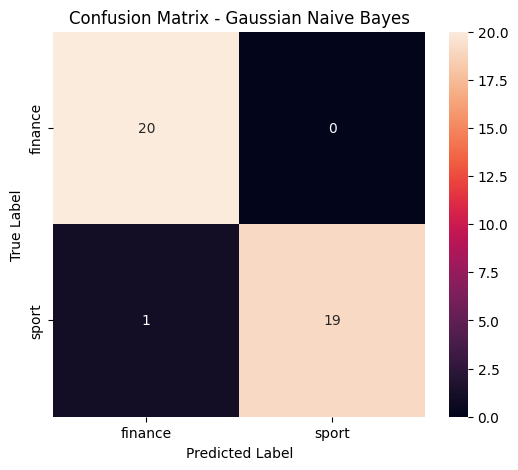

In [33]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["finance", "sport"],
    yticklabels=["finance", "sport"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Gaussian Naive Bayes")

plt.show()

In [34]:
hasil_evaluasi = pd.DataFrame({
    "Metrik": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Nilai": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(hasil_evaluasi)

,Metrik,Nilai
0,Accuracy,0.975000
1,Precision,0.976190
2,Recall,0.975000
3,F1-Score,0.974984


In [35]:
hasil_preprocessing = df[[
    "id",
    "isi_berita",
    "label",
    "clean_text",
    "tokens_stopword",
    "tokens_stemmed"
]]

display(hasil_preprocessing.head(10))

,id,isi_berita,label,clean_text,tokens_stopword,tokens_stemmed
0,1,Men's World Tennis Championship 2026 sudah mem...,sport,mens world tennis championship sudah memasuki ...,"[mens, world, tennis, championship, memasuki, ...","[mens, world, tennis, championship, pasuk, ser..."
1,2,Barra Ghaisan Zeinatma menunjukkan perkembanga...,sport,barra ghaisan zeinatma menunjukkan perkembanga...,"[barra, ghaisan, zeinatma, menunjukkan, perkem...","[barra, ghaisan, zeinatma, tunjuk, kembang, po..."
2,3,Marco Bezzecchi tak sabar menghadapi MotoGP Sa...,sport,marco bezzecchi tak sabar menghadapi motogp sa...,"[marco, bezzecchi, tak, sabar, menghadapi, mot...","[marco, bezzecchi, tak, sabar, hadap, motogp, ..."
3,4,Marc Marquez masih harus beradaptasi dengan ko...,sport,marc marquez masih harus beradaptasi dengan ko...,"[marc, marquez, beradaptasi, kondisi, lengan, ...","[marc, marquez, adaptasi, kondisi, lengan, kan..."
4,5,Pebalap Mercedes GP Kimi Antonelli tampil luar...,sport,pebalap mercedes gp kimi antonelli tampil luar...,"[pebalap, mercedes, gp, kimi, antonelli, tampi...","[balap, mercedes, gp, kim, antonelli, tampil, ..."
5,6,Selesai sudah Seri IV M-15 Men's World Tennis ...,sport,selesai sudah seri iv m mens world tennis cham...,"[selesai, seri, iv, m, mens, world, tennis, ch...","[selesai, seri, iv, m, mens, world, tennis, ch..."
6,7,Jete Run Festival 2026 baru saja selesai digel...,sport,jete run festival baru saja selesai digelar ak...,"[jete, run, festival, baru, selesai, digelar, ...","[jete, run, festival, baru, selesai, gelar, ak..."
7,8,Menteri Komunikasi dan Digital (Menkomdigi) Me...,sport,menteri komunikasi dan digital menkomdigi meut...,"[menteri, komunikasi, digital, menkomdigi, meu...","[menteri, komunikasi, digital, menkomdigi, meu..."
8,9,Pebalap Mercedes GP Kimi Antonelli berhasil me...,sport,pebalap mercedes gp kimi antonelli berhasil me...,"[pebalap, mercedes, gp, kimi, antonelli, berha...","[balap, mercedes, gp, kim, antonelli, hasil, r..."
9,10,Sean Gelael dan Team WRT 32 akan coba meraih p...,sport,sean gelael dan team wrt akan coba meraih podi...,"[sean, gelael, team, wrt, coba, meraih, podium...","[sean, gelael, team, wrt, coba, raih, podium, ..."
